In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
!pip install phik
import phik
from datetime import timedelta
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


df_raw = pd.read_csv('https://docs.google.com/spreadsheets/d/e/2PACX-1vRynvuyJOxU8-HTFsj0-HIuaD-xdl0rCB34sutVxxZmotb31lKWlyfjmnLJ76Li-bkFB6OHQsCfInKc/pub?gid=1919478314&single=true&output=csv')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 11.9 MB/s eta 0:00:00


# Data Exploration & Data Cleaning


In [ ]:
df_raw

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68
...,...,...,...,...,...,...,...,...,...
995,107,8.50,Clear,High,Evening,Car,13,3.0,54
996,271,16.28,Rainy,Low,Morning,Scooter,8,9.0,71
997,861,15.62,Snowy,High,Evening,Scooter,26,2.0,81
998,436,14.17,Clear,Low,Afternoon,Bike,8,0.0,55


In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


In [ ]:
df_raw['Order_ID'] = df_raw['Order_ID'].astype(str)

In [ ]:
df_raw.describe()

,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,970.000000,1000.000000
mean,10.059970,16.982000,4.579381,56.732000
std,5.696656,7.204553,2.914394,22.070915
min,0.590000,5.000000,0.000000,8.000000
25%,5.105000,11.000000,2.000000,41.000000
50%,10.190000,17.000000,5.000000,55.500000
75%,15.017500,23.000000,7.000000,71.000000
max,19.990000,29.000000,9.000000,153.000000


##Melihat sebaran data

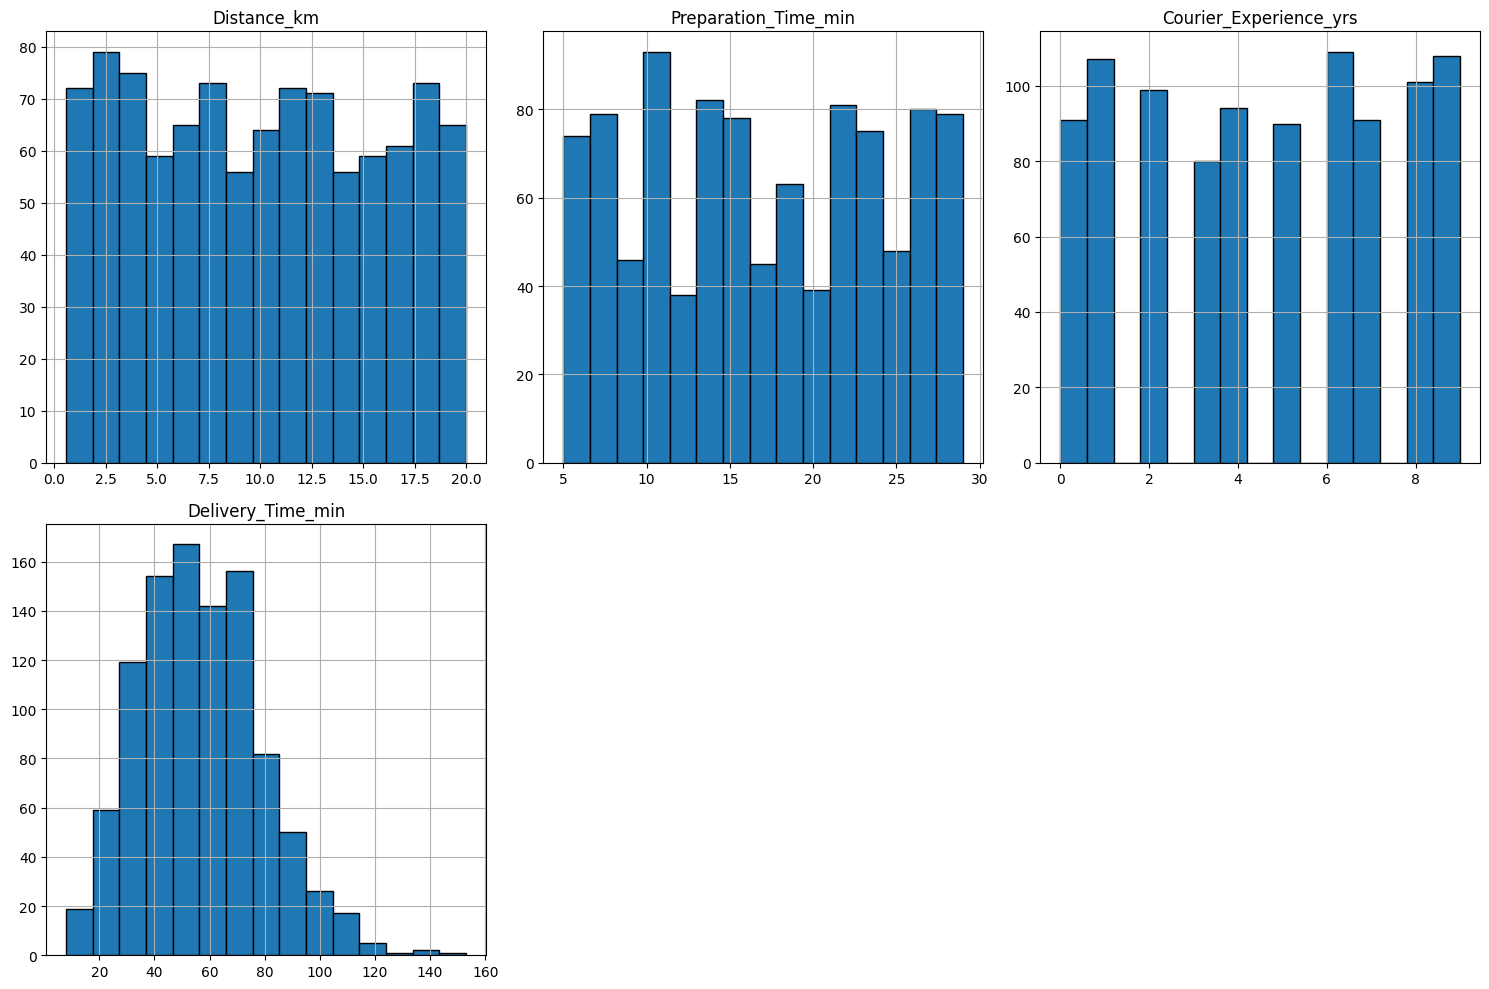

In [ ]:
df_raw.hist(bins=15, figsize=(15, 10), layout=(2, 3), edgecolor="black")


plt.tight_layout()
plt.show()

Sebaran data untuk 'Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Delivery_Time_min', 'Total_Process_Time_min', dan 'Speed_kmh' terlihat bervariasi, beberapa mendekati distribusi normal, sementara yang lain mungkin sedikit miring. Rentang 'Delivery_Time_min' cukup lebar, menunjukkan variasi waktu pengiriman.

/tmp/ipykernel_628/3913902918.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df_raw[col], ax=axes[i], palette="Set2")
/tmp/ipykernel_628/3913902918.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df_raw[col], ax=axes[i], palette="Set2")
/tmp/ipykernel_628/3913902918.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df_raw[col], ax=axes[i], palette="Set2")
/tmp/ipykernel_628/3913902918.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable t

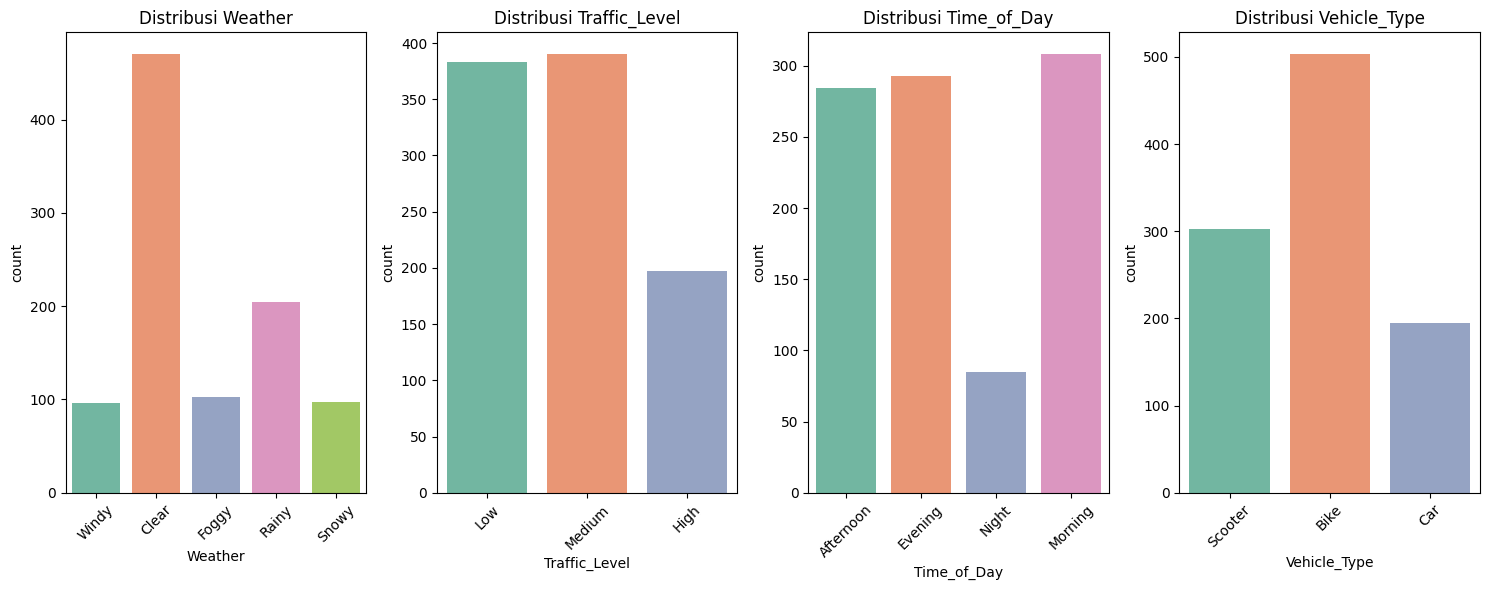

In [ ]:
kolom_kategorikal = ['Weather','Traffic_Level','Time_of_Day','Vehicle_Type']
fig, axes = plt.subplots(nrows=1, ncols=len(kolom_kategorikal), figsize=(15, 6))
if len(kolom_kategorikal) == 1:
    axes = [axes]

# 3. Looping untuk membuat bar chart di setiap kolom
for i, col in enumerate(kolom_kategorikal):
    sns.countplot(x=df_raw[col], ax=axes[i], palette="Set2")
    axes[i].set_title(f"Distribusi {col}")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Weather: 'Clear' adalah kondisi cuaca yang paling sering terjadi.

Traffic_Level: 'Medium' adalah tingkat lalu lintas yang paling dominan.

Time_of_Day: Morning paling banyak, 'Afternoon' dan 'Evening' memiliki jumlah pesanan yang relatif seimbang, sementara 'Night' memiliki paling sedikit.

Vehicle_Type: 'Bike' adalah jenis kendaraan yang paling banyak digunakan, diikuti oleh 'Scooter' dan 'Car'.

## Melihat adanya data null

In [ ]:
df_raw.isnull().sum()

,0
Order_ID,0
Distance_km,0
Weather,30
Traffic_Level,30
Time_of_Day,30
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,30
Delivery_Time_min,0


In [ ]:
df_raw.isnull().mean() *100

,0
Order_ID,0.0
Distance_km,0.0
Weather,3.0
Traffic_Level,3.0
Time_of_Day,3.0
Vehicle_Type,0.0
Preparation_Time_min,0.0
Courier_Experience_yrs,3.0
Delivery_Time_min,0.0


In [ ]:
df = df_raw.copy()

In [ ]:
modus_weather = df['Weather'].mode()[0]
df['Weather'] = df['Weather'].fillna(modus_weather)

In [ ]:
modus_traffic = df['Traffic_Level'].mode()[0]
df['Traffic_Level'] = df['Traffic_Level'].fillna(modus_traffic)

In [ ]:
modus_time = df['Time_of_Day'].mode()[0]
df['Time_of_Day'] = df['Time_of_Day'].fillna(modus_time)

In [ ]:
rata_rata_pengalaman= df['Courier_Experience_yrs'].mean()
df['Courier_Experience_yrs'] = df['Courier_Experience_yrs'].fillna(rata_rata_pengalaman)

Missing Values: Beberapa kolom seperti 'Weather', 'Traffic_Level', 'Time_of_Day', dan 'Courier_Experience_yrs' memiliki 3% missing values. Ini telah ditangani dengan imputasi menggunakan modus (untuk kategorikal) dan mean (untuk numerik).

## Melihat adanya outlier

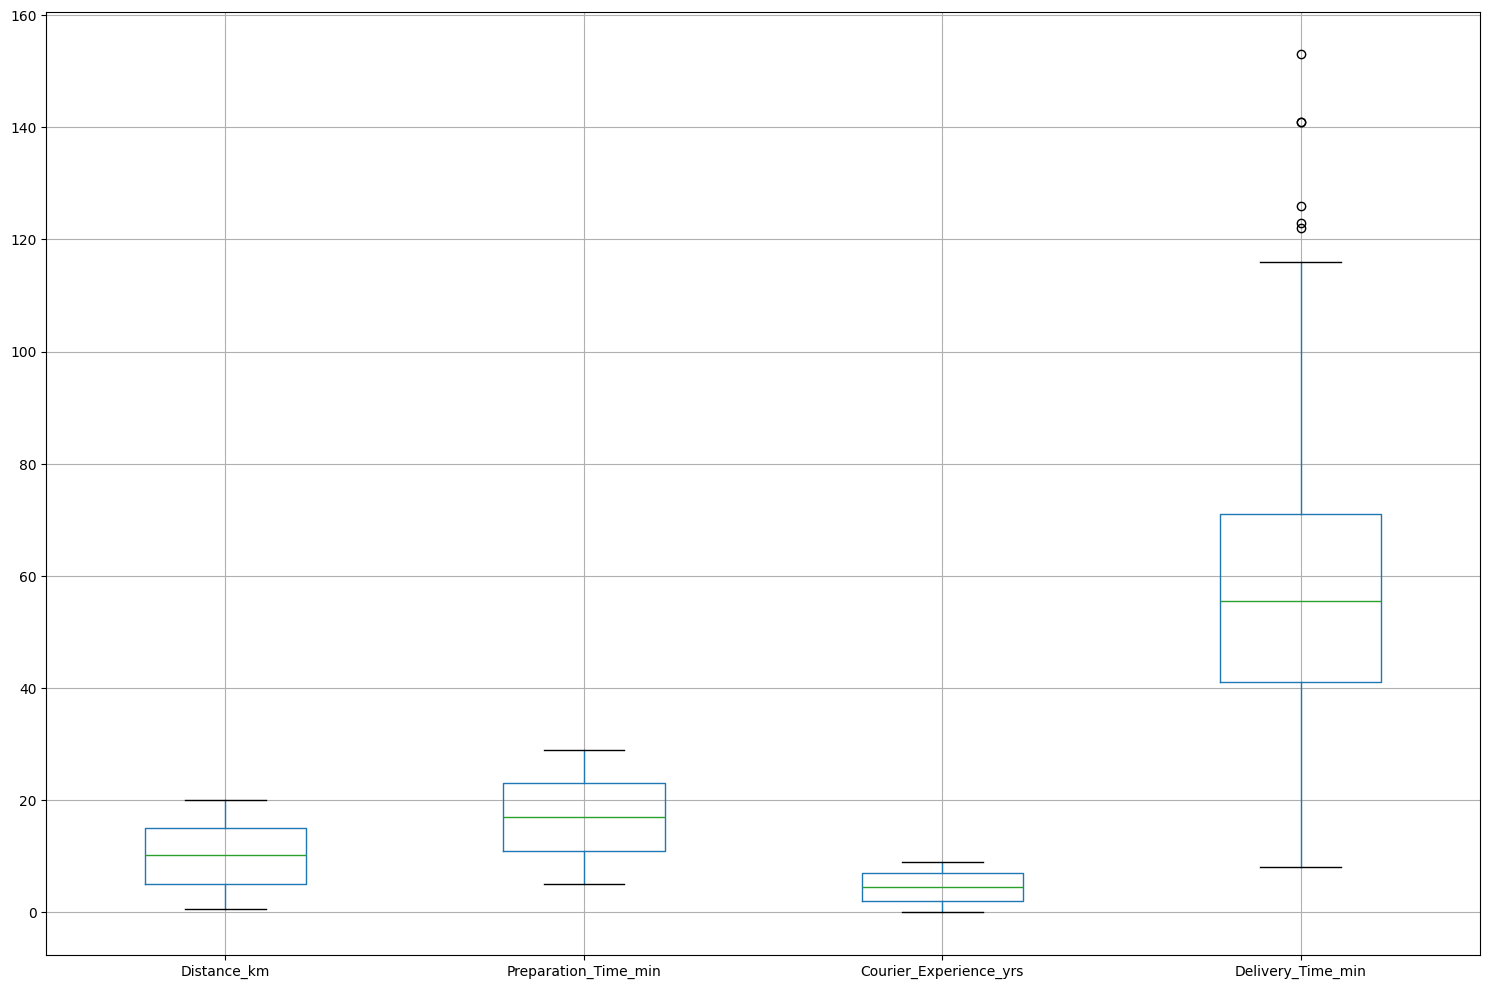

In [ ]:
df.boxplot(figsize=(15, 10))

plt.tight_layout()
plt.show()

In [ ]:

Q1 = df['Delivery_Time_min'].quantile(0.25)
Q3 = df['Delivery_Time_min'].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

df_outlier= df[(df_raw['Delivery_Time_min'] < batas_bawah) | (df['Delivery_Time_min'] > batas_atas)]
df_outlier

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
29,948,18.05,Clear,Medium,Evening,Scooter,10,7.0,123
127,446,18.97,Clear,Low,Evening,Car,25,4.0,141
379,814,18.46,Clear,Medium,Morning,Scooter,29,1.0,153
452,394,15.64,Rainy,Low,Morning,Bike,20,4.0,141
784,385,14.83,Rainy,Low,Morning,Car,19,4.0,126
924,428,17.81,Windy,High,Evening,Bike,21,4.0,122


In [ ]:
persentase_outlier = (len(df_outlier) / len(df)) * 100
print(f"Persentase outlier pada kolom 'Delivery_Time_min': {persentase_outlier:.2f}%")

Persentase outlier pada kolom 'Delivery_Time_min': 0.60%


Outliers: Terdapat outlier pada kolom 'Delivery_Time_min', namun persentasenya sangat kecil (0.6%), sehingga diputuskan untuk tidak menghapusnya.

## Cek adanya duplikat atau tidak

In [ ]:
df.duplicated().sum()

np.int64(0)

Duplikat: Tidak ditemukan data duplikat.

tidak ada data duplikat

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   object 
 1   Distance_km             1000 non-null   float64
 2   Weather                 1000 non-null   object 
 3   Traffic_Level           1000 non-null   object 
 4   Time_of_Day             1000 non-null   object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  1000 non-null   float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(2), object(5)
memory usage: 70.4+ KB


# Data Manipulation


## Feature Engineering

In [ ]:
# 1. Menghitung total waktu dari pesanan dibuat sampai selesai (Waktu Siap + Waktu Perjalanan)

df['Total_Process_Time_min'] = df['Preparation_Time_min'] + df['Delivery_Time_min']

# 2. Menghitung kecepatan kurir

df['Speed_kmh'] = df['Distance_km'] / (df['Delivery_Time_min'] / 60)

# 3. Kategori pengalaman kurir

def kategori_kurir(exp):
    if exp < 2: return 'Junior'
    elif exp <= 5: return 'Mid'
    else: return 'Senior'

df['Courier_Class'] = df['Courier_Experience_yrs'].apply(kategori_kurir)

# 4. Kategori kecepatan kurir

def kategori_kecepatan(speed):
    if speed < 10: return 'Slow'
    elif speed <= 20: return 'Medium'
    else: return 'Fast'

df['Courier_Speed'] = df['Speed_kmh'].apply(kategori_kecepatan)

df

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Total_Process_Time_min,Speed_kmh,Courier_Class,Courier_Speed
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43,55,11.065116,Junior,Medium
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84,104,11.728571,Mid,Medium
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59,87,9.681356,Junior,Slow
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37,42,12.064865,Junior,Medium
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68,84,16.791176,Mid,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,107,8.50,Clear,High,Evening,Car,13,3.0,54,67,9.444444,Mid,Slow
996,271,16.28,Rainy,Low,Morning,Scooter,8,9.0,71,79,13.757746,Senior,Medium
997,861,15.62,Snowy,High,Evening,Scooter,26,2.0,81,107,11.570370,Mid,Medium
998,436,14.17,Clear,Low,Afternoon,Bike,8,0.0,55,63,15.458182,Junior,Medium


## Data Aggregation


In [ ]:
group_by_weather = df.groupby('Weather')[['Courier_Experience_yrs','Distance_km', 'Delivery_Time_min','Speed_kmh']].mean().sort_values(by='Speed_kmh', ascending = False)
group_by_weather

,Courier_Experience_yrs,Distance_km,Delivery_Time_min,Speed_kmh
Weather,,,,
Clear,4.432540,9.777240,53.150000,10.458295
Windy,4.870619,10.033542,55.458333,10.294589
Rainy,4.982727,10.388824,59.794118,10.002177
Snowy,4.679350,11.321649,67.113402,9.609264
Foggy,4.127755,9.617573,59.466019,9.387469


In [ ]:
group_by_traffic_level = df.groupby('Traffic_Level')[['Courier_Experience_yrs','Distance_km', 'Delivery_Time_min','Speed_kmh']].mean().sort_values(by='Speed_kmh', ascending = False)
group_by_traffic_level

,Courier_Experience_yrs,Distance_km,Delivery_Time_min,Speed_kmh
Traffic_Level,,,,
Low,4.493349,10.157467,52.885117,11.012804
Medium,4.523697,9.789405,56.452381,9.868489
High,4.865362,10.447259,64.807107,9.107670


In [ ]:
group_by_time_of_day = df.groupby('Time_of_Day')[[ 'Courier_Experience_yrs','Distance_km', 'Delivery_Time_min','Speed_kmh']].mean().sort_values(by='Speed_kmh', ascending = False)
group_by_time_of_day

,Courier_Experience_yrs,Distance_km,Delivery_Time_min,Speed_kmh
Time_of_Day,,,,
Morning,4.402227,10.335237,57.011834,10.401932
Afternoon,4.729628,10.040880,56.080986,10.193687
Evening,4.660329,9.919761,57.481229,9.986870
Night,4.502802,9.512471,55.211765,9.645495


In [ ]:
group_by_Vehicle = df.groupby('Vehicle_Type')[['Courier_Experience_yrs','Distance_km', 'Delivery_Time_min','Speed_kmh']].mean().sort_values(by='Delivery_Time_min', ascending = False)
group_by_Vehicle

,Courier_Experience_yrs,Distance_km,Delivery_Time_min,Speed_kmh
Vehicle_Type,,,,
Car,4.547375,10.337436,58.200000,10.179891
Bike,4.591830,9.989761,56.574553,10.054843
Scooter,4.579313,9.997748,56.046358,10.311970


In [ ]:
group_by_courier_class = df.groupby('Courier_Class')[['Courier_Experience_yrs','Distance_km', 'Delivery_Time_min','Speed_kmh']].mean().sort_values(by='Speed_kmh', ascending = False)
group_by_courier_class

,Courier_Experience_yrs,Distance_km,Delivery_Time_min,Speed_kmh
Courier_Class,,,,
Senior,7.508557,10.183325,54.904645,10.631396
Mid,3.565856,9.865903,56.801527,9.921858
Junior,0.540404,10.190354,60.368687,9.643177


In [ ]:
group_by_courier_speed = df.groupby('Courier_Speed')[['Courier_Experience_yrs','Distance_km', 'Delivery_Time_min','Speed_kmh']].mean().sort_values(by='Speed_kmh', ascending = False)
group_by_courier_speed

,Courier_Experience_yrs,Distance_km,Delivery_Time_min,Speed_kmh
Courier_Speed,,,,
Fast,6.200000,16.583000,45.700000,21.835770
Medium,4.736661,13.746015,63.845018,13.069234
Slow,4.352927,5.454911,48.372768,6.372762


## Data Sorting

In [ ]:
#Berdasarkan jarak

df_sorted_distance = df.sort_values(by='Distance_km', ascending=True)

df_sorted_distance

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Total_Process_Time_min,Speed_kmh,Courier_Class,Courier_Speed
910,822,0.59,Clear,Low,Afternoon,Bike,21,0.0,27,48,1.311111,Junior,Slow
197,209,0.60,Clear,Low,Afternoon,Bike,26,3.0,30,56,1.200000,Mid,Slow
139,73,0.61,Clear,Low,Afternoon,Scooter,10,0.0,16,26,2.287500,Junior,Slow
871,129,0.64,Clear,High,Night,Bike,10,3.0,24,34,1.600000,Mid,Slow
920,206,0.68,Snowy,High,Evening,Bike,29,8.0,50,79,0.816000,Senior,Slow
...,...,...,...,...,...,...,...,...,...,...,...,...,...
464,391,19.81,Clear,Low,Afternoon,Bike,27,1.0,74,101,16.062162,Junior,Medium
956,476,19.86,Rainy,High,Evening,Bike,12,8.0,71,83,16.783099,Senior,Medium
339,533,19.93,Snowy,Low,Afternoon,Bike,6,6.0,59,65,20.267797,Senior,Fast
815,848,19.94,Clear,Low,Afternoon,Bike,26,6.0,83,109,14.414458,Senior,Medium


In [ ]:
#Berdasarkan waktu pengantaran

df_sorted_delivery_time = df.sort_values(by='Delivery_Time_min', ascending=True)

df_sorted_delivery_time

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Total_Process_Time_min,Speed_kmh,Courier_Class,Courier_Speed
43,975,1.11,Clear,Low,Morning,Bike,5,6.000000,8,13,8.325000,Senior,Slow
242,515,1.38,Clear,Medium,Evening,Scooter,5,8.000000,13,18,6.369231,Senior,Slow
323,629,1.22,Clear,Medium,Evening,Scooter,6,4.579381,14,20,5.228571,Mid,Slow
95,437,1.92,Clear,Low,Morning,Bike,8,7.000000,14,22,8.228571,Senior,Slow
749,920,3.23,Clear,Low,Morning,Bike,7,7.000000,14,21,13.842857,Senior,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...
29,948,18.05,Clear,Medium,Evening,Scooter,10,7.000000,123,133,8.804878,Senior,Slow
784,385,14.83,Rainy,Low,Morning,Car,19,4.000000,126,145,7.061905,Mid,Slow
127,446,18.97,Clear,Low,Evening,Car,25,4.000000,141,166,8.072340,Mid,Slow
452,394,15.64,Rainy,Low,Morning,Bike,20,4.000000,141,161,6.655319,Mid,Slow


In [ ]:
#Berdasarkan pengalaman kurir

df_courier_experience = df.sort_values(by='Courier_Experience_yrs', ascending=False)

df_courier_experience

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Total_Process_Time_min,Speed_kmh,Courier_Class,Courier_Speed
996,271,16.28,Rainy,Low,Morning,Scooter,8,9.0,71,79,13.757746,Senior,Medium
965,22,3.22,Clear,Medium,Afternoon,Bike,19,9.0,32,51,6.037500,Senior,Slow
966,314,19.27,Foggy,Medium,Morning,Car,29,9.0,85,114,13.602353,Senior,Medium
28,903,4.04,Snowy,Low,Night,Bike,11,9.0,70,81,3.462857,Senior,Slow
32,622,4.58,Clear,High,Morning,Scooter,22,9.0,45,67,6.106667,Senior,Slow
...,...,...,...,...,...,...,...,...,...,...,...,...,...
706,148,10.30,Rainy,Low,Evening,Bike,29,0.0,73,102,8.465753,Junior,Slow
274,524,16.92,Clear,Low,Morning,Scooter,29,0.0,70,99,14.502857,Junior,Medium
944,485,11.89,Clear,Medium,Afternoon,Bike,28,0.0,79,107,9.030380,Junior,Slow
224,897,6.22,Rainy,Medium,Morning,Bike,15,0.0,49,64,7.616327,Junior,Slow


In [ ]:
#Berdasarkan kecepatan kurir

df_sorted_speed = df.sort_values(by='Speed_kmh', ascending=False)

df_sorted_speed

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Total_Process_Time_min,Speed_kmh,Courier_Class,Courier_Speed
92,523,19.41,Clear,Low,Morning,Car,7,3.0,48,55,24.262500,Mid,Fast
929,898,17.98,Clear,Low,Evening,Bike,5,8.0,45,50,23.973333,Senior,Fast
7,514,17.39,Clear,Medium,Evening,Scooter,5,6.0,46,51,22.682609,Senior,Fast
157,698,11.83,Clear,Low,Evening,Scooter,9,7.0,32,41,22.181250,Senior,Fast
16,281,17.86,Rainy,Low,Afternoon,Bike,5,1.0,50,55,21.432000,Junior,Fast
...,...,...,...,...,...,...,...,...,...,...,...,...,...
197,209,0.60,Clear,Low,Afternoon,Bike,26,3.0,30,56,1.200000,Mid,Slow
751,875,1.00,Snowy,Medium,Morning,Bike,28,0.0,51,79,1.176471,Junior,Slow
200,30,1.41,Foggy,Medium,Evening,Bike,15,0.0,72,87,1.175000,Junior,Slow
585,408,0.71,Foggy,Low,Night,Bike,29,1.0,41,70,1.039024,Junior,Slow


#Exploratory Data Analysis

##Heatmap Kategorikal

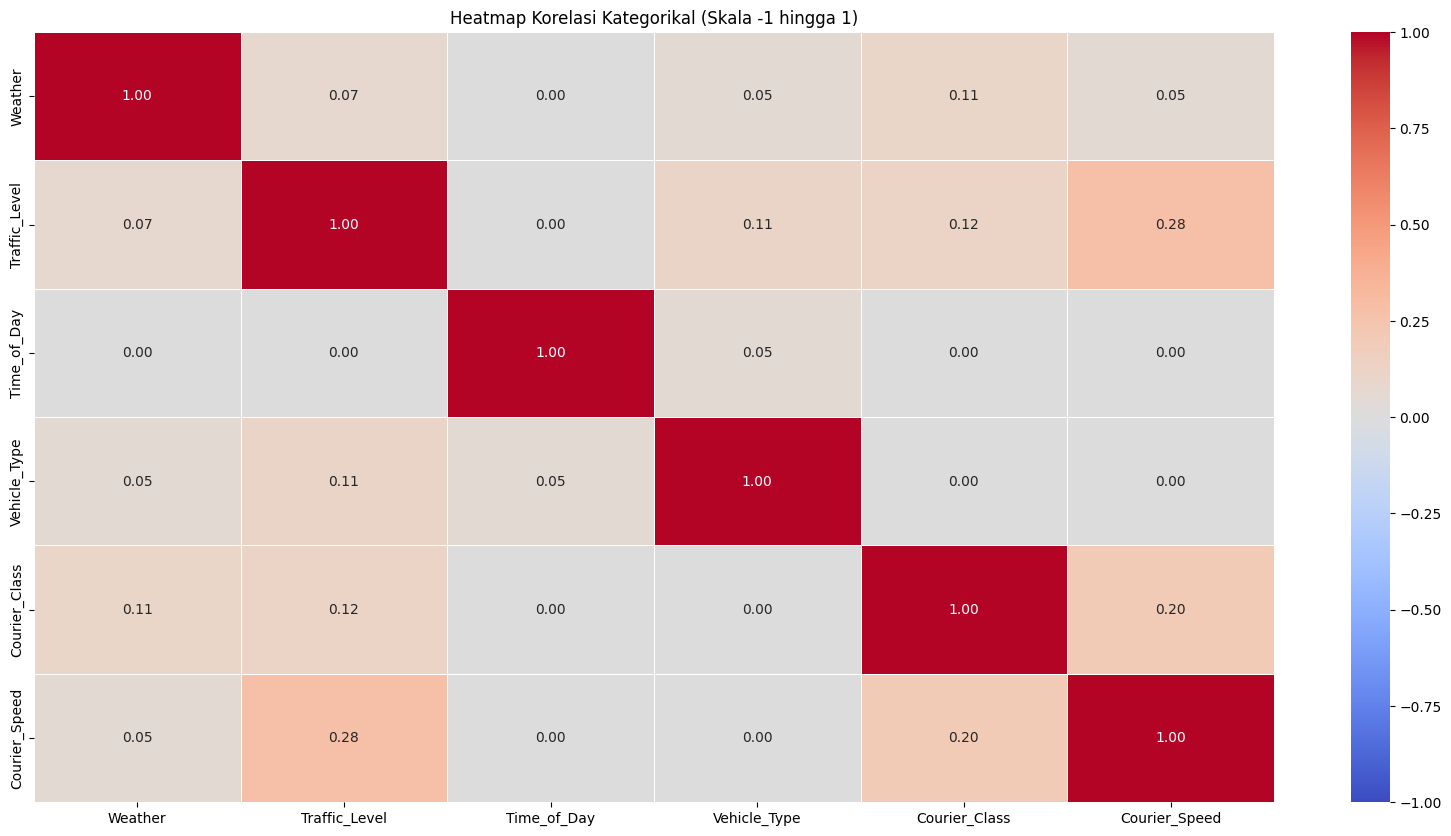

In [ ]:
kolom_kat = ['Weather','Traffic_Level',"Time_of_Day",'Vehicle_Type',"Courier_Class","Courier_Speed"]
matriks_korelasi = df[kolom_kat].phik_matrix()

# 3. Membuat Heatmap dengan skala -1 sampai 1
plt.figure(figsize=(20, 10))
sns.heatmap(
    matriks_korelasi,
    annot=True,  # Menampilkan nilai korelasi
    cmap="coolwarm",  # Warna coolwarm sangat cocok untuk rentang negatif-positif
    vmin=-1,  # Batas bawah skala
    vmax=1,  # Batas atas skala
    fmt=".2f",
    linewidths=0.5,
)

plt.title("Heatmap Korelasi Kategorikal (Skala -1 hingga 1)")
plt.savefig('Heatmap kategorikal')
plt.show()


### Bivariate Analysis

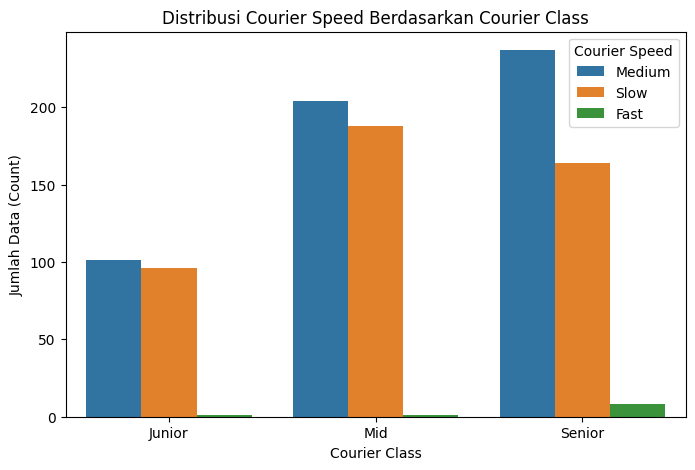

In [ ]:


plt.figure(figsize=(8, 5))
# Urutkan sumbu X secara manual menggunakan order
sns.countplot(
    data=df,
    x="Courier_Class",
    hue="Courier_Speed",
    order=["Junior", "Mid", "Senior"],
)

plt.title("Distribusi Courier Speed Berdasarkan Courier Class")
plt.xlabel("Courier Class")
plt.ylabel("Jumlah Data (Count)")
plt.legend(title="Courier Speed")
plt.savefig('Distribusi Courier Speed by Courier Class')
plt.show()

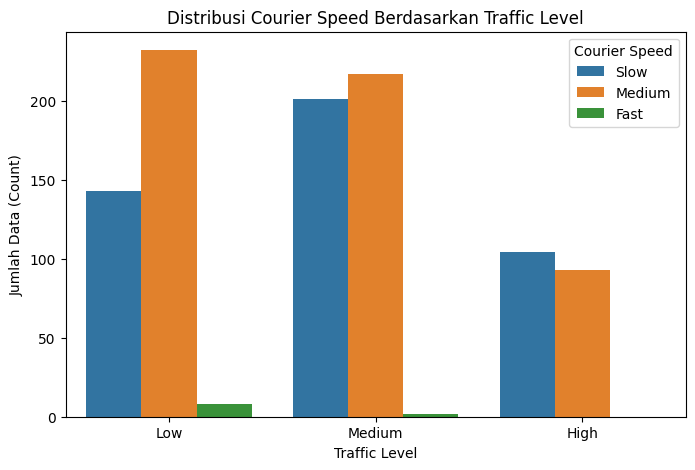

In [ ]:
courier_speed = pd.CategoricalDtype(
    categories=["Slow", "Medium", "Fast"], ordered=True
)
df["Courier_Speed"] = df["Courier_Speed"].astype(courier_speed)

plt.figure(figsize=(8, 5))
# Urutkan sumbu X secara manual menggunakan order
sns.countplot(
    data=df,
    x="Traffic_Level",
    hue="Courier_Speed",
    order=["Low", "Medium", "High"],
)

plt.title("Distribusi Courier Speed Berdasarkan Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Jumlah Data (Count)")
plt.legend(title="Courier Speed")
plt.savefig('Distribusi courier speed by traffic level')
plt.show()

### Univariate analysis


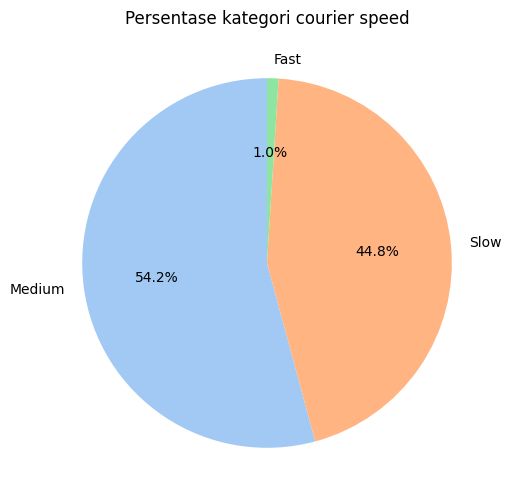

In [ ]:
plt.figure(figsize=(6, 6))


df["Courier_Speed"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("pastel"),
)

plt.title("Persentase kategori courier speed")
plt.ylabel("")
plt.savefig('Persentase kategori courier speed')
plt.show()

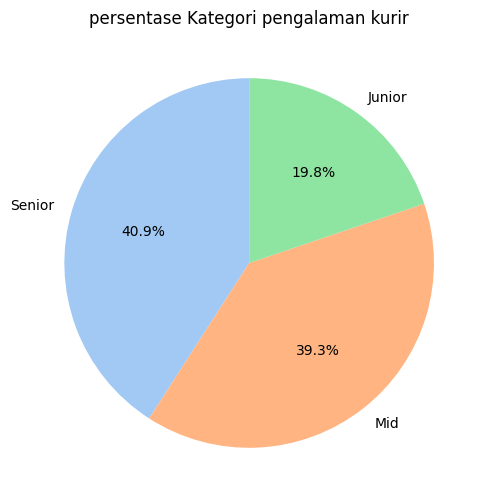

In [ ]:
plt.figure(figsize=(6, 6))

# Membuat pie chart dari data value_counts
df["Courier_Class"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",  # Menampilkan persentase otomatis
    startangle=90,
    colors=sns.color_palette("pastel"),
)

plt.title("persentase Kategori pengalaman kurir")
plt.ylabel("")
plt.savefig('Persentase kategori pengalaman kurir')
plt.show()

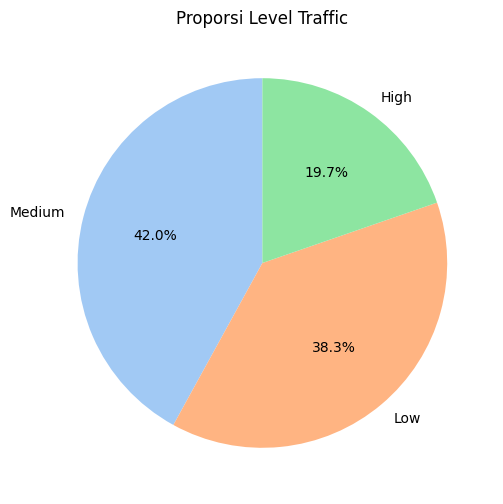

In [ ]:
plt.figure(figsize=(6, 6))

# Membuat pie chart dari data value_counts
df["Traffic_Level"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("pastel"),
)

plt.title("Proporsi Level Traffic")
plt.ylabel("")
plt.savefig('Persentase level traffic')
plt.show()

## Heatmap Numerikal

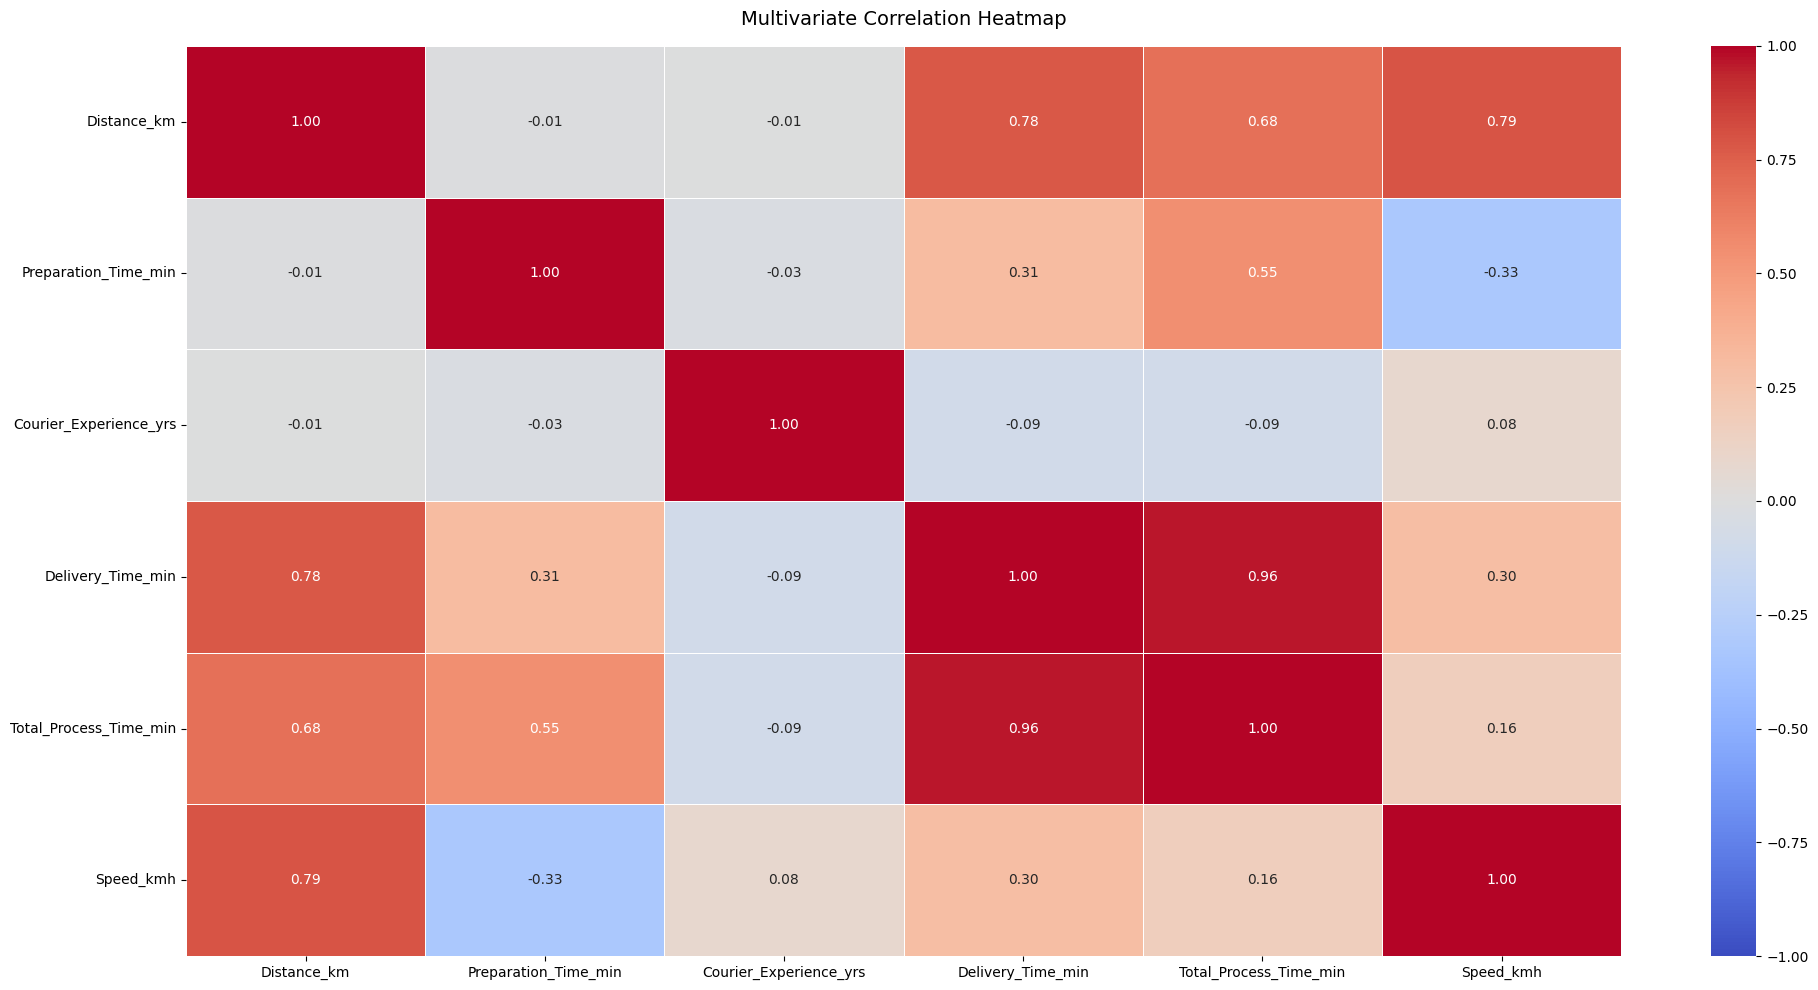

In [ ]:
corr_matrix = df.select_dtypes(include=[np.number]).corr()

plt.figure(figsize=(20, 10))

sns.heatmap(
    corr_matrix,
    annot=True,  # Show correlation values inside each cell
    cmap="coolwarm",  # Diverging color palette (blue = negative, red = positive)
    vmin=-1,  # Anchor the minimum value of the color scale
    vmax=1,  # Anchor the maximum value of the color scale
    linewidths=0.5,  # Add space between cells for clean formatting
    fmt=".2f"  # Round cell values to 2 decimal places
)

# 5. Add custom details and display
plt.title("Multivariate Correlation Heatmap", fontsize=14, pad=15)
plt.tight_layout()
plt.savefig('Heatmap Numerikal')
plt.show()

### Bivariate analysis

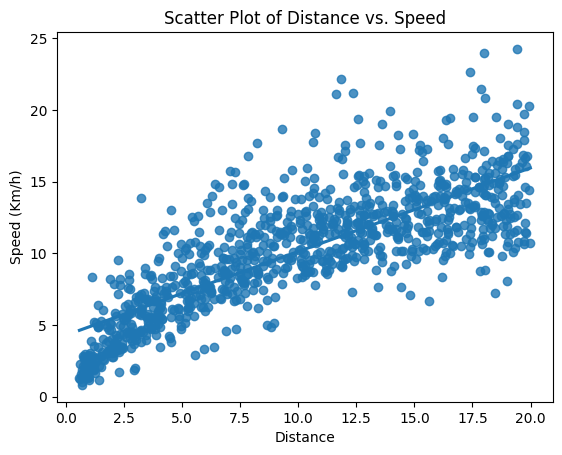

In [ ]:
sns.regplot(x=df['Distance_km'], y=df['Speed_kmh'], ci=None)  # ci=None untuk menghilangkan area interval kepercayaan (confidence interval)

# Menampilkan judul dan label
plt.title("Scatter Plot of Distance vs. Speed")
plt.xlabel("Distance")
plt.ylabel("Speed (Km/h)")

# Menampilkan grafik
plt.savefig('Scatter plot distance vs speed')
plt.show()

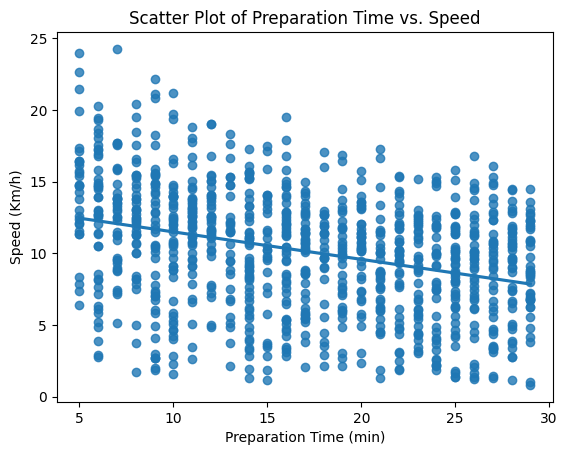

In [ ]:
sns.regplot(x=df['Preparation_Time_min'], y=df['Speed_kmh'], ci=None)  # ci=None untuk menghilangkan area interval kepercayaan (confidence interval)

# Menampilkan judul dan label
plt.title("Scatter Plot of Preparation Time vs. Speed")
plt.xlabel("Preparation Time (min)")
plt.ylabel("Speed (Km/h)")

# Menampilkan grafik
plt.savefig('scatter plot preparation time vs speed')
plt.show()

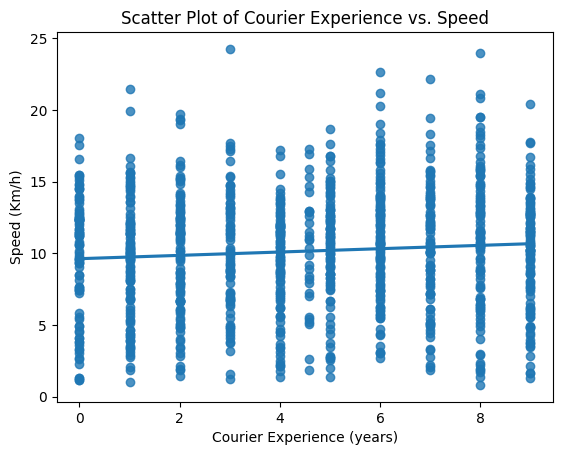

In [ ]:
sns.regplot(x=df['Courier_Experience_yrs'], y=df['Speed_kmh'], ci=None)  # ci=None untuk menghilangkan area interval kepercayaan (confidence interval)

# Menampilkan judul dan label
plt.title("Scatter Plot of Courier Experience vs. Speed")
plt.xlabel("Courier Experience (years)")
plt.ylabel("Speed (Km/h)")

# Menampilkan grafik
plt.savefig('Scatter plot courier experience vs speed')
plt.show()

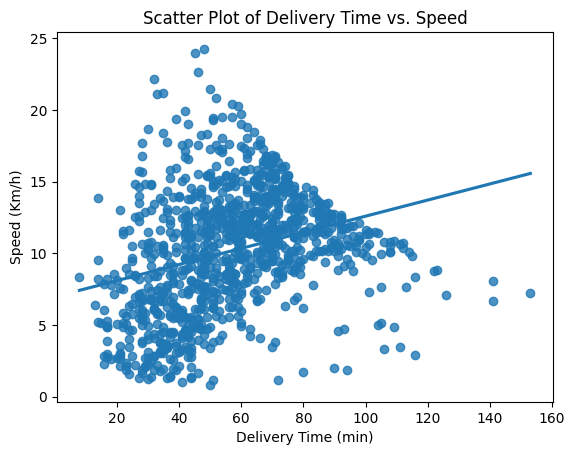

In [ ]:
sns.regplot(x=df['Delivery_Time_min'], y=df['Speed_kmh'], ci=None)  # ci=None untuk menghilangkan area interval kepercayaan (confidence interval)

# Menampilkan judul dan label
plt.title("Scatter Plot of Delivery Time vs. Speed")
plt.xlabel("Delivery Time (min)")
plt.ylabel("Speed (Km/h)")

# Menampilkan grafik
plt.savefig('Scatter plot delivery time vs speed')
plt.show()

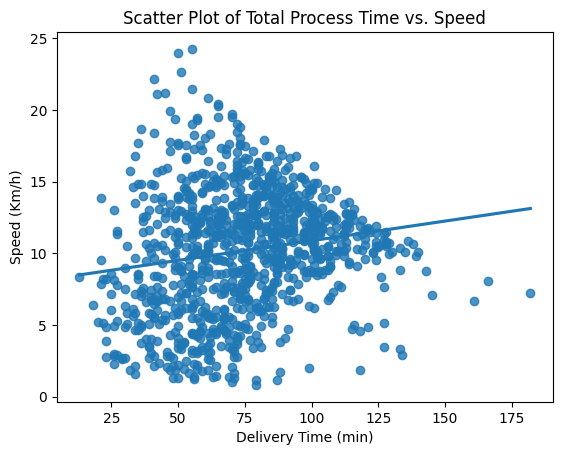

In [ ]:
sns.regplot(x=df['Total_Process_Time_min'], y=df['Speed_kmh'], ci=None)  # ci=None untuk menghilangkan area interval kepercayaan (confidence interval)

# Menampilkan judul dan label
plt.title("Scatter Plot of Total Process Time vs. Speed")
plt.xlabel("Delivery Time (min)")
plt.ylabel("Speed (Km/h)")

# Menampilkan grafik
plt.savefig('Scatter plot total process time vs speed')
plt.show()

### Univariate Analysis

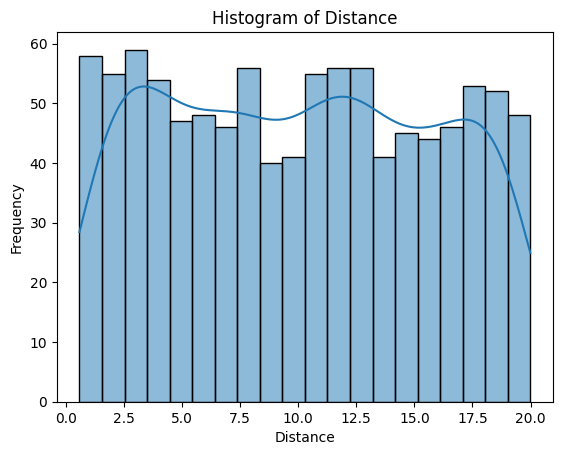

In [ ]:
## for numerinal variable

sns.histplot(df['Distance_km'], bins=20, kde=True)
plt.title("Histogram of Distance")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.savefig('Histogram fo distance')
plt.show()

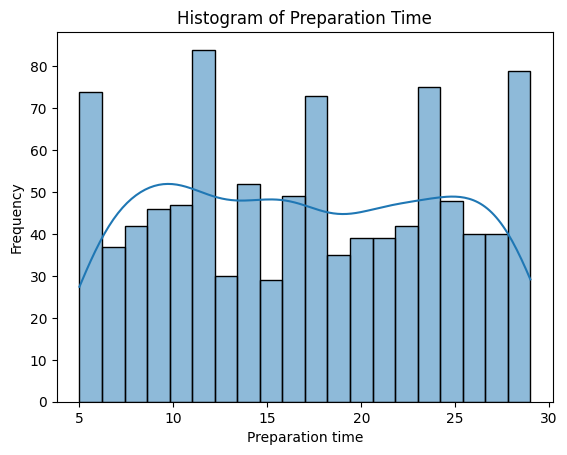

In [ ]:
## for numerical variable

sns.histplot(df['Preparation_Time_min'], bins=20, kde=True)
plt.title("Histogram of Preparation Time")
plt.xlabel("Preparation time")
plt.ylabel("Frequency")
plt.savefig('Histogram of prepartion time')
plt.show()

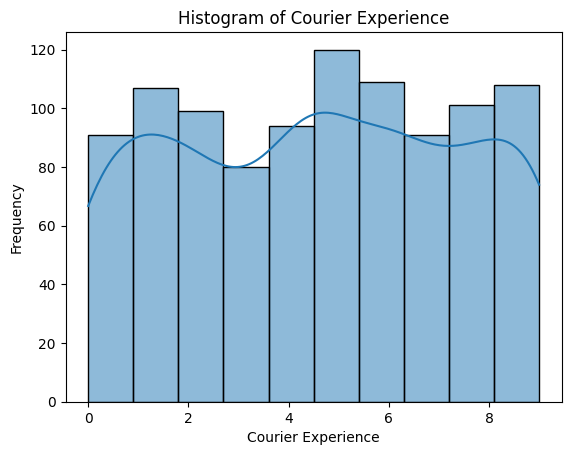

In [ ]:
## for numerical variable

sns.histplot(df['Courier_Experience_yrs'], bins=10, kde=True)
plt.title("Histogram of Courier Experience")
plt.xlabel("Courier Experience")
plt.ylabel("Frequency")
plt.savefig('Histogram of courier experience')
plt.show()

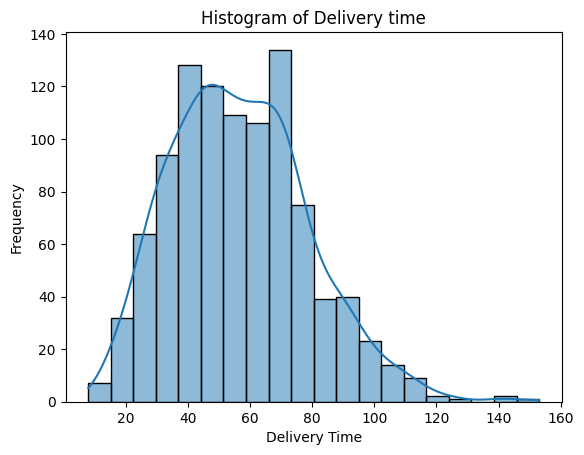

In [ ]:
## for numerinal variable

sns.histplot(df['Delivery_Time_min'], bins=20, kde=True)
plt.title("Histogram of Delivery time")
plt.xlabel("Delivery Time")
plt.ylabel("Frequency")
plt.savefig('Histogram of delivery time')
plt.show()

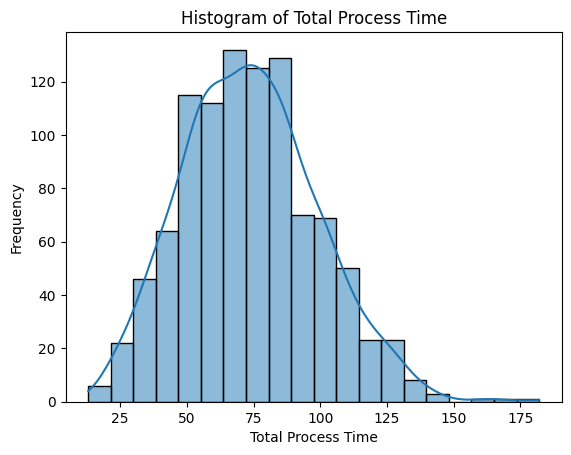

In [ ]:
## for numerinal variable

sns.histplot(df['Total_Process_Time_min'], bins=20, kde=True)
plt.title("Histogram of Total Process Time")
plt.xlabel("Total Process Time")
plt.ylabel("Frequency")
plt.savefig('Histogram of total process time')
plt.show()

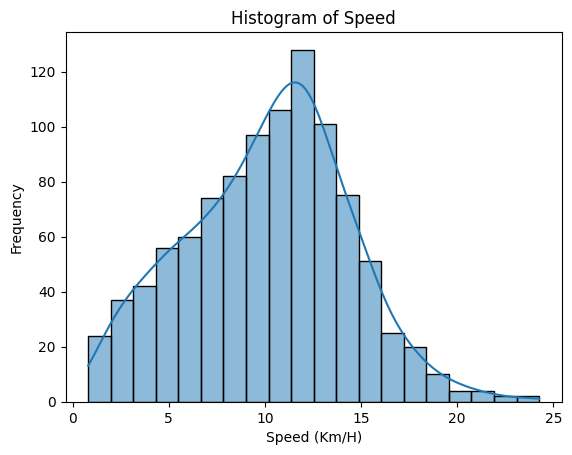

In [ ]:
## for numerinal variable

sns.histplot(df['Speed_kmh'], bins=20, kde=True)
plt.title("Histogram of Speed")
plt.xlabel("Speed (Km/H)")
plt.ylabel("Frequency")
plt.savefig('Histogram of speed')
plt.show()

# Insights




Strategi pengiriman dapat dioptimalkan dengan mempertimbangkan faktor-faktor ini, seperti rute yang lebih efisien untuk jarak jauh, penugasan kurir berpengalaman pada kondisi sulit, atau insentif untuk kurir agar menjaga kecepatan optimal.

1.   cuaca dan traffic level adalah prediktor paling signifikan untuk waktu pengiriman.
2.   Kondisi lalu lintas (terutama 'High' traffic) dan cuaca buruk ('Snowy') berdampak negatif pada waktu pengiriman.
3. Pengalaman kurir berperan dalam efisiensi pengiriman; kurir senior cenderung lebih cepat, namun tidak semua kurir senior secara otomatis 'Fast'.
4. Jenis kendaraan 'Scooter' menunjukkan efisiensi waktu pengiriman yang lebih baik.




#Export Data

In [ ]:
df.to_csv('df_logistic.csv', index=False)